# Ovarian tumor cohort: Fig. 5 and Supplementary Fig. S8

Fig. 5 drawn as one figure, from the outputs of the ovarian analysis (`04a_ovarian.ipynb` → `04b_ovarian_within_donor.ipynb` → `04c_ovarian_chromvar.R` → `04d_ovarian_motif.ipynb`). Run after those steps.

- Fit: `output/v2/ovarian_bkg/202610/11/080711` (see `04a_ovarian.ipynb`).
- From `04a`: the donor and the cell-type group of each cell (`fig5_cells.csv`), the clones (`clones.csv`), the table of d (`fig5d_phi.csv`, `fig5d_rows.csv`) and the capture of the variants (`fig5e_capture.csv`, `fig5e_correlations.csv`).
- From `04d`: the two motif tests of Clone 11 (`motif/clone11_motifs.csv`) and the tested cells with their genotype (`motif/r_input/groups.csv`).
- Output: `analysis/results/ovarian/figure5.pdf` and `supfig8.pdf` (and `.png`).

In [1]:
%cd ../src

.../cloneVI/src


.../site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [2]:
import subprocess

import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import seaborn as sns
from adjustText import adjust_text
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib_venn import venn2
from scipy.stats import norm

In [3]:
RUN = '../output/v2/ovarian_bkg/202610/11/080711'
OUT = '../analysis/results/ovarian'
MOTIF = f'{OUT}/motif'
LABELS = '../data/mitotrek/paper_supp/tableS2_ovarian_tumor_labels.csv'   # cell types of the source study (S8a)

### Figure style

As in `03e_cll_figure4.ipynb`: one matplotlib figure at the text width of the manuscript (505.7 pt), printed without scaling; the positions of the panels are decided first from sizes shared by all figures, and each panel is drawn into its axes by the standard functions. All maps have the same size (the UMAP undistorted), each with its colorbar on the right; panel letters stand in the letter column at the left of their panel, on the top line of the titles. Colours as in `04a` and `04d`.

In [4]:
plt.rcParams.update({'font.size': 6.5, 'axes.titlesize': 7, 'axes.labelsize': 6.5, 'xtick.labelsize': 6,
                     'ytick.labelsize': 6, 'legend.fontsize': 6, 'axes.linewidth': 0.5, 'xtick.major.width': 0.5,
                     'ytick.major.width': 0.5, 'xtick.major.size': 2, 'ytick.major.size': 2, 'savefig.dpi': 600})
PI_CMAP = sns.cubehelix_palette(start=.5, rot=-.5, as_cmap=True)
VAF_CMAP = sns.cubehelix_palette(as_cmap=True)
DIM = '#e2e1dd'                     # cells not covered, and cells without a label (as in 04a)
GROUP_COL = {'tumor': '#8a6fae', 'stromal': '#c0a14a', 'CD8+ T': '#1f6f55', 'other T/NK': '#9ccf6e', 'myeloid': '#d9a07a',
             'B/plasma': '#b7879a', 'no label': DIM}        # as in 04a
CAT_COL = {'both': '#3d3c39', 'pi_only': '#2a78d6', 'genotype_only': '#eb6834', 'none': '#d5d4cf'}   # as in 04d
CAT_NAME = {'both': 'both', 'pi_only': r'$\pi$-weighted only', 'genotype_only': 'mutation-based only', 'none': 'neither'}
den = lambda M: M.toarray() if sp.issparse(M) else np.asarray(M)

# sizes shared by all figures (points), as in 03e_cll_figure4.ipynb
W = 505.69                          # text width
M = 1                               # outer margin, so that frames at the edge are drawn whole
MB = 4                              # bottom margin below a map: half of its lowest colorbar label hangs below it
LG = 9                              # letter column at the left of every column (the gap between columns)
CL = 3                              # clearance at the right of a panel that has no colorbar beside it
GY = 6                              # gap between rows
T = 11                              # title row above a panel; titles and letters stand on its baseline
PAD = 3                             # baseline of the titles above the axes
CB_W, CB_PAD, CB_ROOM = 4, 3, 26    # colorbar beside a map: width, distance, and the room it takes with its labels
SW = (W - 2 * M) / 4                # width of a column (4 columns), letter column included
MW = SW - LG - CB_ROOM              # width of a map
LH = 1.2 * plt.rcParams['axes.titlesize']   # height of a line of a title
plt.rcParams['axes.titlepad'] = PAD

## 1. The data

The clone of 12879T>C is found by the rule of `04a` (the largest $\phi$ above the shared component). Cells not covered by 12879T>C (depth below 10) have no VAF and are drawn in grey.

In [5]:
fit = sc.read_h5ad(f'{RUN}/cloneVI_result.h5ad')
variants = np.array([str(v) for v in fit.var_names])
col = {m: j for j, m in enumerate(variants)}
pi_all = np.asarray(fit.obsm['pi_sorted'], dtype=float)
kept = np.flatnonzero((pi_all.mean(0) > 0.01) | (pi_all.max(0) >= 0.2))
LABEL = {i: int(k) for i, k in enumerate(kept)}
phi = np.asarray(fit.varm['phi_deleted'], dtype=float)
phi0 = np.asarray(fit.varm['phi_0'], dtype=float).mean(1)
i12 = int((phi - phi0[:, None])[col['12879T>C']].argmax())
K12 = LABEL[i12]                                              # the clone of 12879T>C (the rule of 04a)
j12 = col['12879T>C']
d12 = den(fit.X[:, j12]).ravel()
v12 = den(fit.layers['VAF'][:, j12]).ravel()
tab = pd.read_csv(f'{OUT}/fig5_cells.csv', index_col=0)
assert (tab.index == fit.obs_names).all()
DONORS = sorted(set(tab['donor']))
DONOR_COL = dict(zip(DONORS, plt.get_cmap('tab10')(np.arange(len(DONORS)))))
cells = sc.AnnData(obs=pd.DataFrame(index=fit.obs_names))
cells.obsm['X_umap'] = np.asarray(fit.obsm['X_cloneVI_umap'])
cells.obs['Donor'] = pd.Categorical(tab['donor'], categories=DONORS)
cells.obs['Cell type'] = pd.Categorical(tab['cell type'], categories=list(GROUP_COL))
cells.obs[f'Clone {K12} probability'] = np.asarray(fit.obsm['pi_deleted'], dtype=float)[:, i12]
cells.obs['12879T>C VAF'] = np.where(d12 >= 10, v12, np.nan)        # cells not covered: no value (drawn in grey)
clones = pd.read_csv(f'{OUT}/clones.csv')
Md = pd.read_csv(f'{OUT}/fig5d_phi.csv', index_col=0)
rows = pd.read_csv(f'{OUT}/fig5d_rows.csv', index_col=0)
cap = pd.read_csv(f'{OUT}/fig5e_capture.csv', index_col=0)
corr = pd.read_csv(f'{OUT}/fig5e_correlations.csv', index_col=0)
T12 = pd.read_csv(f'{MOTIF}/clone{K12}_motifs.csv')
E = T12[T12['eligible']]
DONOR12 = tab['donor'].to_numpy()[np.asarray(fit.obsm['pi_deleted'])[:, i12].argmax()]   # the donor of Clone 11 (04d: SU-O-005)
assert list(Md.index) == list(rows.index)
pd.Series({'cells': fit.n_obs, 'clone of 12879T>C': K12, 'its donor': DONOR12, 'rows x clones of d': Md.shape, 'variants of e': len(cap), 'motifs of f-h': len(E)}, dtype=object)

cells                   108260
clone of 12879T>C           11
its donor             SU-O-005
rows x clones of d    (19, 17)
variants of e               64
motifs of f-h              746
dtype: object

## 2. Fig. 5

a, b, the donors and the cell-type groups of the source study on the CloneVI UMAP, with their legends below. c, the clonal probability of Clone 11 and the VAF of 12879T>C. d, the clone-specific allele frequencies $\phi$ of the variants carried at $\phi \geq 0.1$ (rows and columns as in `04a`; left, the donors of the mutant cells; boxes, $\phi$ at least 0.8 times the mean VAF of the mutant cells; white lines between the clones of different donors). e, which mutant-cell populations CloneVI captures, with the Spearman correlation and the partial Spearman correlation of each property with the AUC in each plot (not in the titles: titles say what a panel shows). f–h, the motifs significant in the mutation-based and the $\pi$-weighted tests of Clone 11 (`04d`). The cell size of d is the one at which d and e are equally high.

.../site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
.../site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
.../site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
.../site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Par

figure 505.69 x 458.4 pt; maps 90.9 x 91.0 pt (point size 0.138); d cells 5.54 pt (19 x 17); e plots 94.9 pt


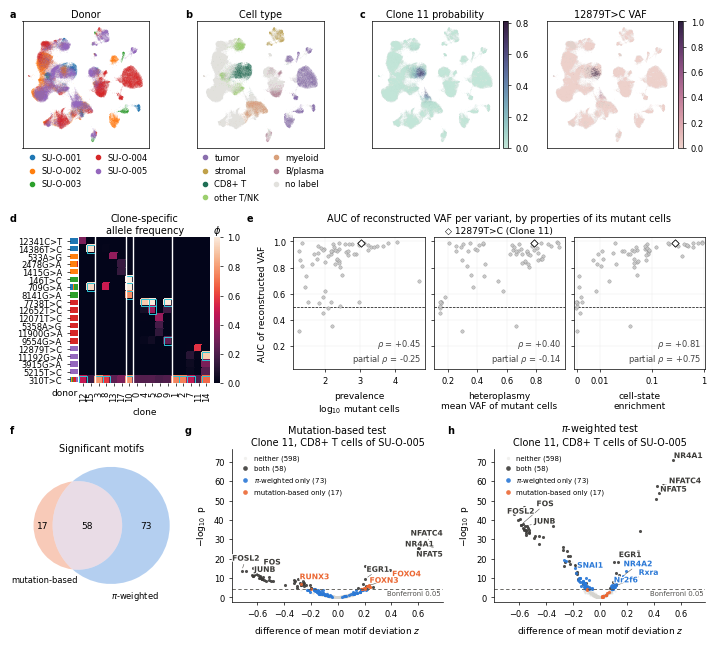

In [6]:
# the positions of the panels (points, from the top left)
u = cells.obsm['X_umap']
MH = MW * np.ptp(u[:, 1]) / np.ptp(u[:, 0])
SIZE = 1.8 * MW * MH / len(u)
col_x = lambda j: M + j * SW

def legend_size(**kw):
    f = plt.figure(figsize=(W / 72, 3))
    b = f.legend(**kw).get_window_extent(f.canvas.get_renderer())
    plt.close(f)
    return b.width * 72 / f.dpi, b.height * 72 / f.dpi

LEG = dict(frameon=False, handletextpad=0.1, columnspacing=1.0, borderaxespad=0, borderpad=0)
leg_a = dict(handles=[Line2D([], [], marker='o', ls='', markersize=3, color=DONOR_COL[d], label=d) for d in DONORS], ncol=2, **LEG)
leg_b = dict(handles=[Line2D([], [], marker='o', ls='', markersize=3, color=c, label=g) for g, c in GROUP_COL.items()], ncol=2, **LEG)
y0 = M
y_leg = y0 + T + MH + 4                                     # the legends of a and b, below their maps
y1 = y_leg + max(legend_size(**leg_a)[1], legend_size(**leg_b)[1]) + GY

# row 1: d (heatmap with the donor strip) and e (three scatter plots); the cell of d is the size at which d and e are
# equally high
nv, nk = Md.shape
LV, STRIP, BD = 34, 6, 22                                   # variant names, donor strip, below d (clone numbers, 'clone')
L1 = 25                                                     # y labels of e
GXE = 6                                                     # gap between the plots of e
BX = lambda n: 2 + 3.5 + 1.2 * 6 + 4 + n * 1.2 * 6.5        # below a scatter plot: ticks, labels, an n-line x label
fixed_d = LG + LV + STRIP + 1 + CB_ROOM                     # width of d without its cells
e_room = W - 2 * M - fixed_d - LG - L1 - 2 * GXE - CL       # width of the three plots of e, less the cells of d
# both under a title row of two lines: nv*c + BD == EW + BX(2), with EW = (e_room - nk*c) / 3
c = (BX(2) - BD + e_room / 3) / (nv + nk / 3)
EW = (e_room - nk * c) / 3
xd = M + LG + LV + STRIP + 1                                # left of the heatmap
xe = M + fixed_d + nk * c                                   # left of the slot of e
y2 = y1 + T + LH + nv * c + BD + GY

# row 2: f (Venn), g and h (volcano plots)
FV = SW                                                     # slot of f
GW = (W - 2 * M - FV) / 2                                   # slots of g and h
VH = 110                                                    # height of a volcano plot
H = y2 + (T + LH) + VH + BX(1) + MB
fig = plt.figure(figsize=(W / 72, H / 72))

def axes(x, y, w, h):
    return fig.add_axes([x / W, 1 - (y + h) / H, w / W, h / H])

def letter(x, y, s):
    fig.text(x / W, 1 - (y + T - PAD) / H, s, fontweight='bold', fontsize=plt.rcParams['axes.titlesize'], va='baseline')

emb = dict(basis='umap', show=False, frameon=True, size=SIZE, colorbar_loc=None)
def umap(x, y, color, **kw):
    ax = axes(x, y + T, MW, MH)
    sc.pl.embedding(cells, color=color, ax=ax, **emb, **kw)
    ax.set_xlabel(''); ax.set_ylabel('')
    for pc in ax.collections:                # the points as an image at savefig.dpi (600); text and frames stay vector
        pc.set_rasterized(True)
    if 'cmap' in kw:
        fig.colorbar(ax.collections[-1], cax=axes(x + MW + CB_PAD, y + T, CB_W, MH))
    return ax

# a, b, c
for j, (lt, colname, pal, leg) in enumerate([('a', 'Donor', [DONOR_COL[d] for d in DONORS], leg_a),
                                              ('b', 'Cell type', list(GROUP_COL.values()), leg_b)]):
    letter(col_x(j), y0, lt)
    umap(col_x(j) + LG, y0, colname, palette=pal, legend_loc=None)
    fig.legend(loc='upper center', bbox_to_anchor=((col_x(j) + LG + MW / 2) / W, 1 - y_leg / H), **leg)
letter(col_x(2), y0, 'c')
umap(col_x(2) + LG, y0, f'Clone {K12} probability', cmap=PI_CMAP, vmin=0)
umap(col_x(3) + LG, y0, '12879T>C VAF', cmap=VAF_CMAP, vmin=0, na_color=DIM)

# d
letter(M, y1, 'd')
ax = axes(xd, y1 + T + LH, nk * c, nv * c)
sns.heatmap(Md.to_numpy(), ax=ax, vmin=0, vmax=1, square=True, linewidths=0.3, linecolor='face', xticklabels=list(Md.columns), yticklabels=False,
            cbar_ax=axes(xd + nk * c + CB_PAD, y1 + T + LH, CB_W, nv * c))
fig.axes[-1].set_title(r'$\phi$')
cdonor = clones.set_index('clone')['donor'].reindex(Md.columns.astype(int)).to_numpy()
for b in np.flatnonzero(cdonor[1:] != cdonor[:-1]) + 1:
    ax.axvline(b, color='white', lw=1.0)
for r_, o in enumerate(rows['mutant VAF']):
    for k in range(nk):
        if Md.iat[r_, k] >= 0.8 * o:
            ax.add_patch(Rectangle((k, r_), 1, 1, fill=False, edgecolor='#2ec4d6', lw=0.7))
ax.set_xlabel('clone')
ax.tick_params(axis='x', rotation=90)
ax.set_title('Clone-specific\nallele frequency')
axd = axes(xd - 1 - STRIP, y1 + T + LH, STRIP, nv * c)
left = np.zeros(nv)
for d in DONORS:
    axd.barh(np.arange(nv) + 0.5, rows[d].to_numpy(), left=left, height=0.72, color=DONOR_COL[d], edgecolor='none')
    left += rows[d].to_numpy()
axd.set_xlim(0, 1); axd.set_ylim(nv, 0)
axd.set_yticks(np.arange(nv) + 0.5)
axd.set_yticklabels(rows.index)
axd.set_xticks([])
axd.set_xlabel('donor', loc='right')
for s_ in axd.spines.values():
    s_.set_visible(False)

# e
XLAB = {'prevalence': 'prevalence\nlog$_{10}$ mutant cells', 'heteroplasmy': 'heteroplasmy\nmean VAF of mutant cells',
        'enrichment': 'cell-state\nenrichment'}
PROPS = ['prevalence', 'heteroplasmy', 'enrichment']
letter(xe, y1, 'e')
eax = [axes(xe + LG + L1 + i * (EW + GXE), y1 + T + LH, EW, EW) for i in range(3)]
for ax, x in zip(eax, PROPS):
    rest = cap.drop(index='12879T>C')
    ax.scatter(rest[x], rest['auc'], s=6, c='#c8c8c8', edgecolor='#8a8a8a', lw=0.25, zorder=2)
    ax.scatter(cap.loc['12879T>C', x], cap.loc['12879T>C', 'auc'], marker='D', s=14, c='white', edgecolor='k', lw=0.6, zorder=4)
    ax.axhline(0.5, color='k', lw=0.5, ls='--', zorder=1)
    if x == 'enrichment':
        ax.set_xscale('symlog', linthresh=0.01, linscale=0.4)
        ax.set_xticks([0, 0.01, 0.1, 1]); ax.set_xticklabels(['0', '0.01', '0.1', '1'])
        ax.set_xlim(-0.0015, 1.08)
    ax.set_xlabel(XLAB[x])
    ax.grid(alpha=0.25, lw=0.3)
lo, hi = min(a.get_ylim()[0] for a in eax), max(a.get_ylim()[1] for a in eax)
for ax in eax:
    ax.set_ylim(lo, hi)
for ax in eax[1:]:
    ax.tick_params(labelleft=False)
eax[0].set_ylabel('AUC of reconstructed VAF')
# rho and partial rho in each plot (not in the titles), at the bottom: the y range of the three plots is extended
# downwards by the height of the two lines, so that a band without points holds them; of its two corners, the one
# farther from the points
fig.canvas.draw()                                    # the axis limits are final only after drawing
renderer = fig.canvas.get_renderer()
label = lambda x: f'$\\rho$ = {corr.loc[x, "rho"]:+.2f}\npartial $\\rho$ = {corr.loc[x, "partial rho"]:+.2f}'
t = eax[0].text(0, 0, label(PROPS[0]), transform=eax[0].transAxes, fontsize=plt.rcParams['legend.fontsize'])
f_text = (t.get_window_extent(renderer).height + 6) / eax[0].get_window_extent(renderer).height   # with 3 px above and below
t.remove()
lo, hi = eax[0].get_ylim()
lo = lo - (hi - lo) * f_text / (1 - f_text)
CORNERS = {(0.97, 0.03): 'right', (0.03, 0.03): 'left'}
ticks = [v for v in eax[0].get_yticks() if 0 <= v <= 1]   # AUC ticks only (the band below holds no values)
for ax, x in zip(eax, PROPS):
    ax.set_ylim(lo, hi)
    ax.set_yticks(ticks)
    pa = ax.transAxes.inverted().transform(ax.transData.transform(np.c_[cap[x], cap['auc']]))
    best = max(CORNERS, key=lambda c: np.min(np.hypot(pa[:, 0] - c[0], (pa[:, 1] - c[1]) * 1.5)))
    ax.text(*best, label(x), transform=ax.transAxes, ha=CORNERS[best], va='bottom', color='#444',
            fontsize=plt.rcParams['legend.fontsize'])
ex0, ex1 = xe + LG + L1, xe + LG + L1 + 3 * EW + 2 * GXE
fig.text((ex0 + ex1) / 2 / W, 1 - (y1 + T - PAD) / H, 'AUC of reconstructed VAF per variant, by properties of its mutant cells', ha='center', va='baseline',
         fontsize=plt.rcParams['axes.titlesize'])
fig.text((ex0 + ex1) / 2 / W, 1 - (y1 + T + LH - PAD) / H, f'◇ 12879T>C (Clone {K12})', ha='center', va='baseline')

# f
n = {k: int((E['category'] == k).sum()) for k in ('both', 'pi_only', 'genotype_only')}
letter(M, y2, 'f')
ax = axes(M + LG, y2 + T + LH, FV - LG - CL, VH)
v = venn2(subsets=(n['genotype_only'], n['pi_only'], n['both']), set_labels=('mutation-based', r'$\pi$-weighted'),
          set_colors=(CAT_COL['genotype_only'], CAT_COL['pi_only']), alpha=0.35, ax=ax)
for t in v.set_labels:
    t.set_fontsize(6)
ax.set_title('Significant motifs')

# g, h
ANNOTATE = {'genotype': {'both': ['NR4A1', 'NFATC4', 'NFAT5', 'EGR1', 'FOS', 'JUNB', 'FOSL2'],
                         'genotype_only': ['FOXO4', 'FOXN3', 'RUNX3']},
            'pi': {'both': ['NR4A1', 'NFATC4', 'NFAT5', 'EGR1', 'FOS', 'JUNB', 'FOSL2'],
                   'pi_only': ['NR4A2', 'Nr2f6', 'Rxra', 'SNAI1']}}   # as in 04d
lp = {s: -np.log10(np.maximum(2 * norm.sf(np.abs(E[f'{s}__z'].to_numpy())), 1e-300)) for s in ('genotype', 'pi')}
ymax = max(lp['genotype'].max(), lp['pi'].max()) * 1.08
xlim = np.abs(np.r_[E['genotype__avg_diff'], E['pi__avg_diff']]).max() * 1.1
thr = -np.log10(0.05 / len(T12))
title = f'Clone {K12}, CD8+ T cells of {DONOR12}'
for i, (lt, side, ttl) in enumerate([('g', 'genotype', f'Mutation-based test\n{title}'), ('h', 'pi', f'$\\pi$-weighted test\n{title}')]):
    x0 = M + FV + i * GW
    letter(x0, y2, lt)
    ax = axes(x0 + LG + L1, y2 + T + LH, GW - LG - L1 - CL, VH)
    eff = E[f'{side}__avg_diff'].to_numpy()
    for cat in ('none', 'both', 'pi_only', 'genotype_only'):
        m = (E['category'] == cat).to_numpy()
        ax.scatter(eff[m], lp[side][m], s=(5 if cat != 'none' else 2.5), color=CAT_COL[cat],
                   alpha=(0.9 if cat != 'none' else 0.35), linewidths=0, rasterized=True, label=f'{CAT_NAME[cat]} ({int(m.sum())})')
    ax.axhline(thr, color='#52514e', lw=0.6, ls=(0, (4, 3)))
    ax.text(xlim * 0.98, thr - 0.6, 'Bonferroni 0.05', fontsize=5, color='#52514e', va='top', ha='right')
    texts = []
    for cat, tfs in ANNOTATE[side].items():
        m = ((E['category'] == cat) & E['tf'].isin(tfs)).to_numpy()
        for x_, y_, nm in zip(eff[m], lp[side][m], E['tf'].to_numpy()[m]):
            texts.append(ax.text(x_, y_, nm, fontsize=5.5, color=CAT_COL[cat], fontweight='bold',
                                 path_effects=[pe.withStroke(linewidth=1.6, foreground='white')], zorder=6))
    ax.set_xlim(-xlim, xlim); ax.set_ylim(-ymax * 0.03, ymax)
    adjust_text(texts, x=eff, y=lp[side], ax=ax, arrowprops=dict(arrowstyle='-', color='#52514e', lw=0.4),
                iter_lim=1000)   # iterations, not seconds (the default, 1 s): the same every run
    ax.set_xlabel('difference of mean motif deviation $z$')
    ax.set_ylabel('$-\\log_{10}$ p')
    ax.legend(frameon=False, fontsize=5, loc='upper left', handletextpad=0.2, markerscale=1.5)
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_title(ttl)
fig.savefig(f'{OUT}/figure5.pdf')
fig.savefig(f'{OUT}/figure5.png', dpi=300)
print(f'figure {W} x {H:.1f} pt; maps {MW:.1f} x {MH:.1f} pt (point size {SIZE:.3f}); d cells {c:.2f} pt ({nv} x {nk}); e plots {EW:.1f} pt')

## 3. Supplementary Fig. S8

a–c, the tested cells of Clone 11 (`04d`), enlarged: the region of their coordinates (0.5–99.5% quantiles, as in `04d`), widened to the aspect of the maps so that all four maps have the same size undistorted. a, the cell types of the source study at its finer level; b, the clonal probability of Clone 11; c, the 12879T>C genotype; other cells in light grey. d, the 902 mutant cells of 3109T>C on the cohort UMAP (`04a`), with the covered non-mutant cells in grey. Point sizes by the rule of all maps (the points cover 1.8 times the area of a map), with the cells in view.

figure 505.69 x 154.3 pt; maps 90.9 x 91.0 pt; tested cells 2077, in view 19194; point sizes 0.78, 0.138


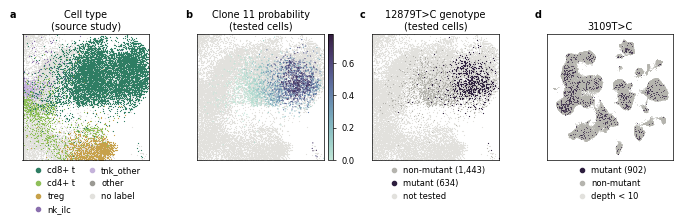

In [7]:
xy = np.asarray(fit.obsm['X_cloneVI_umap'])
MH = MW * np.ptp(xy[:, 1]) / np.ptp(xy[:, 0])
groups = pd.read_csv(f'{MOTIF}/r_input/groups.csv', index_col=0)       # the tested cells and their genotype (04d)
rows12 = fit.obs_names.get_indexer(groups.index)
assert (rows12 >= 0).all()
g12 = (groups['genotype'] == 'pos').to_numpy()
pi12 = np.asarray(fit.obsm['pi_deleted'], dtype=float)[:, i12]
lv1 = pd.read_csv(LABELS, index_col=0).reindex(fit.obs_names)['cell_type_lv1'].to_numpy()
LV1_COL = {'cd8+ t': '#2e7d63', 'cd4+ t': '#8fbf5a', 'treg': '#c7a14a', 'nk_ilc': '#8a6fae', 'tnk_other': '#c4b2da',
           'other': '#9a9993', 'no label': DIM}                                          # as in 04d
lv1_in = np.where(pd.isna(lv1), 'no label', np.where(np.isin(lv1, list(LV1_COL)[:5]), lv1, 'other'))
j3109 = col['3109T>C']
d3109, v3109 = den(fit.X[:, j3109]).ravel(), den(fit.layers['VAF'][:, j3109]).ravel()
cov3109 = d3109 >= 10
m3109 = cov3109 & (v3109 >= 0.10) & (np.rint(d3109 * v3109) >= 3)                   # mutant, as in 04a

# the region of the tested cells (0.5-99.5% quantiles, as in 04d), widened to the aspect of the maps
(x0, x1), (y0, y1) = (np.quantile(xy[rows12, a], [0.005, 0.995]) for a in (0, 1))
cxz, cyz = (x0 + x1) / 2, (y0 + y1) / 2
half = max((x1 - x0) / 2, (y1 - y0) / 2 * MW / MH)
xlimz, ylimz = (cxz - half, cxz + half), (cyz - half * MH / MW, cyz + half * MH / MW)
inview = (xy[:, 0] >= xlimz[0]) & (xy[:, 0] <= xlimz[1]) & (xy[:, 1] >= ylimz[0]) & (xy[:, 1] <= ylimz[1])
tested = np.zeros(fit.n_obs, bool); tested[rows12] = True
SZ = 1.8 * MW * MH / inview.sum()                    # point size of the enlarged maps (the rule of all maps)
SF = 1.8 * MW * MH / fit.n_obs                       # and of the map of the cohort

LEG = dict(frameon=False, handletextpad=0.1, columnspacing=1.0, borderaxespad=0, borderpad=0)
dot = lambda c, lab: Line2D([], [], marker='o', ls='', markersize=3, color=c, label=lab)
leg_a = dict(handles=[dot(c, t) for t, c in LV1_COL.items()], ncol=2, **LEG)
leg_c = dict(handles=[dot('#b5b4ae', f'non-mutant ({int((~g12).sum()):,})'), dot(VAF_CMAP(1.0), f'mutant ({int(g12.sum()):,})'),
                      dot(DIM, 'not tested')], ncol=1, **LEG)
leg_d = dict(handles=[dot(VAF_CMAP(1.0), f'mutant ({int(m3109.sum()):,})'), dot('#b5b4ae', 'non-mutant'), dot(DIM, 'depth < 10')],
             ncol=1, **LEG)

def legend_height(**kw):
    f = plt.figure(figsize=(W / 72, 3))
    b = f.legend(**kw).get_window_extent(f.canvas.get_renderer())
    plt.close(f)
    return b.height * 72 / f.dpi

T2 = T + LH                                          # title row of two lines
y_leg = M + T2 + MH + 4
H = y_leg + max(legend_height(**k) for k in (leg_a, leg_c, leg_d)) + MB
fig = plt.figure(figsize=(W / 72, H / 72))
axes = lambda x, y, w, h: fig.add_axes([x / W, 1 - (y + h) / H, w / W, h / H])
letter = lambda x, y, s: fig.text(x / W, 1 - (y + T - PAD) / H, s, fontweight='bold', fontsize=plt.rcParams['axes.titlesize'],
                                  va='baseline')
col_x = lambda j: M + j * SW

def frame(j, title, zoom=True):                      # an empty map in column j, as drawn by sc.pl.embedding
    ax = axes(col_x(j) + LG, M + T2, MW, MH)
    ax.set_xticks([]); ax.set_yticks([])
    if zoom:
        ax.set_xlim(*xlimz); ax.set_ylim(*ylimz)
    ax.set_title(title)
    letter(col_x(j), M, 'abcd'[j])
    return ax

def dots(ax, m, s, **kw):
    ax.scatter(xy[m, 0], xy[m, 1], s=s, linewidths=0, rasterized=True, **kw)

ax = frame(0, 'Cell type\n(source study)')
for t_, c_ in reversed(LV1_COL.items()):            # cells without a label and other cells below
    dots(ax, inview & (lv1_in == t_), SZ, color=c_)
ax = frame(1, f'Clone {K12} probability\n(tested cells)')
dots(ax, inview & ~tested, SZ, color=DIM)
o = rows12[np.argsort(pi12[rows12])]
dots(ax, o, SZ, c=pi12[o], cmap=PI_CMAP, vmin=0, vmax=pi12[rows12].max())
fig.colorbar(ax.collections[-1], cax=axes(col_x(1) + LG + MW + CB_PAD, M + T2, CB_W, MH))
ax = frame(2, '12879T>C genotype\n(tested cells)')
dots(ax, inview & ~tested, SZ, color=DIM)
dots(ax, rows12[~g12], SZ, color='#b5b4ae')
dots(ax, rows12[g12], SZ, color=VAF_CMAP(1.0))
ax = frame(3, '3109T>C', zoom=False)
dots(ax, ~cov3109, SF, color=DIM)
dots(ax, cov3109 & ~m3109, SF, color='#b5b4ae')
dots(ax, m3109, 2 * SF, color=VAF_CMAP(1.0))
for j, leg in ((0, leg_a), (2, leg_c), (3, leg_d)):
    fig.legend(loc='upper center', bbox_to_anchor=((col_x(j) + LG + MW / 2) / W, 1 - y_leg / H), **leg)
fig.savefig(f'{OUT}/supfig8.pdf')
fig.savefig(f'{OUT}/supfig8.png', dpi=300)
print(f'figure {W} x {H:.1f} pt; maps {MW:.1f} x {MH:.1f} pt; tested cells {len(rows12)}, in view {inview.sum()}; point sizes {SZ:.2f}, {SF:.3f}')